# Factuality Over Time by Jurisdiction

Shows mean factuality scores by year for US, Ontario, and Quebec.
Background shading indicates governing party for Ontario and Quebec.

** Different shades for each premier in the background so the graph shows factuality and governing party simultaneously.

** Factuality by governing era, or gov vs opposition shift over decades.

In [3]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Works whether running from repo root or notebooks/ subfolder
REPO = os.path.dirname(os.path.abspath('__file__')) if '__file__' in dir() else os.path.abspath('..')
# Fallback: set explicitly
REPO = '/Users/caprice/MiscellaneousProjects/legislative-health-factuality'

print('Loading data...')

Loading data...


In [4]:
# ── Load US factuality scores ─────────────────────────────────────────────────
with open(f'{REPO}/data/dbpedia_pipeline/us/factuality_scores.json') as f:
    us_scores = json.load(f)

us_rows = []
for date, v in us_scores.items():
    if v['total_sentences'] > 0:
        us_rows.append({'date': date, 'year': int(date[:4]), 'factuality': v['factuality_score']})
us_df = pd.DataFrame(us_rows)
us_yearly = us_df.groupby('year')['factuality'].agg(['mean','count']).reset_index()
us_yearly.columns = ['year','mean','n']
print(f'US: {len(us_rows)} bill-dates, {us_yearly.year.min()}-{us_yearly.year.max()}')

US: 441 bill-dates, 1985-2026


In [5]:
# ── Load Ontario factuality scores (per-bill) ────────────────────────────────
with open(f'{REPO}/data/dbpedia_pipeline/ontario/factuality_scores_per_bill.json') as f:
    ont_scores = json.load(f)
with open(f'{REPO}/data/canada/ontario/ontario_bill_index.json') as f:
    ont_index = json.load(f)

ont_rows = []
for bill_key, v in ont_scores.items():
    dates = ont_index.get(bill_key, {}).get('dates', [])
    year = int(dates[-1][:4]) if dates else None
    if year and v.get('factuality_score') is not None:
        ont_rows.append({'year': year, 'factuality': v['factuality_score']})
ont_df = pd.DataFrame(ont_rows)
ont_yearly = ont_df.groupby('year')['factuality'].agg(['mean','count']).reset_index()
ont_yearly.columns = ['year','mean','n']
print(f'Ontario: {len(ont_rows)} bills, {ont_yearly.year.min()}-{ont_yearly.year.max()}')

Ontario: 329 bills, 1987-2026


In [6]:
# ── Load Quebec factuality scores ─────────────────────────────────────────────
with open(f'{REPO}/data/dbpedia_pipeline/quebec/factuality_scores.json') as f:
    qc_scores = json.load(f)

qc_rows = []
for date, v in qc_scores.items():
    if v['total_sentences'] > 0:
        qc_rows.append({'date': date, 'year': int(date[:4]), 'factuality': v['factuality_score']})
qc_df = pd.DataFrame(qc_rows)
qc_yearly = qc_df.groupby('year')['factuality'].agg(['mean','count']).reset_index()
qc_yearly.columns = ['year','mean','n']
print(f'Quebec: {len(qc_rows)} bill-dates, {qc_yearly.year.min()}-{qc_yearly.year.max()}')

Quebec: 2448 bill-dates, 1985-2026


In [10]:
# ── Governing periods for background shading ──────────────────────────────────

# US House majority control (start of new Congress after each election)
us_house = [
    (1985, 1995, 'Democrat',   '#D6604D'),  # Dem majority
    (1995, 2007, 'Republican', '#4393C3'),  # Rep majority (Gingrich)
    (2007, 2011, 'Democrat',   '#D6604D'),  # Dem majority (Pelosi)
    (2011, 2019, 'Republican', '#4393C3'),  # Rep majority (Boehner/Ryan)
    (2019, 2023, 'Democrat',   '#D6604D'),  # Dem majority (Pelosi)
    (2023, 2027, 'Republican', '#4393C3'),  # Rep majority
]

# US Presidency
us_presidents = [
    (1985, 1989, 'Reagan',  '#4393C3'),   # R
    (1989, 1993, 'Bush Sr', '#4393C3'),   # R
    (1993, 2001, 'Clinton', '#D6604D'),   # D
    (2001, 2009, 'Bush Jr', '#4393C3'),   # R
    (2009, 2017, 'Obama',   '#D6604D'),   # D
    (2017, 2021, 'Trump',   '#4393C3'),   # R
    (2021, 2025, 'Biden',   '#D6604D'),   # D
    (2025, 2027, 'Trump',   '#4393C3'),   # R
]
# Ontario governing periods
ont_govs = [
    (1985, 1985, 'PC',       '#4393C3'),  # Miller PC minority
    (1985, 1990, 'Liberal',  '#D6604D'),  # Peterson Liberal
    (1990, 1995, 'NDP',      '#F4A582'),  # Rae NDP
    (1995, 2003, 'PC',       '#4393C3'),  # Harris/Eves PC
    (2003, 2018, 'Liberal',  '#D6604D'),  # McGuinty/Wynne Liberal
    (2018, 2027, 'PC',       '#4393C3'),  # Ford PC
]

# Quebec governing periods
qc_govs = [
    (1985, 1994, 'Liberal',  '#D6604D'),  # Bourassa Liberal
    (1994, 2003, 'PQ',       '#74ADD1'),  # Parizeau/Bouchard/Landry PQ
    (2003, 2012, 'Liberal',  '#D6604D'),  # Charest Liberal
    (2012, 2014, 'PQ',       '#74ADD1'),  # Marois PQ minority
    (2014, 2018, 'Liberal',  '#D6604D'),  # Couillard Liberal
    (2018, 2027, 'CAQ',      '#78C679'),  # Legault CAQ
]

print('Governing periods defined')

Governing periods defined


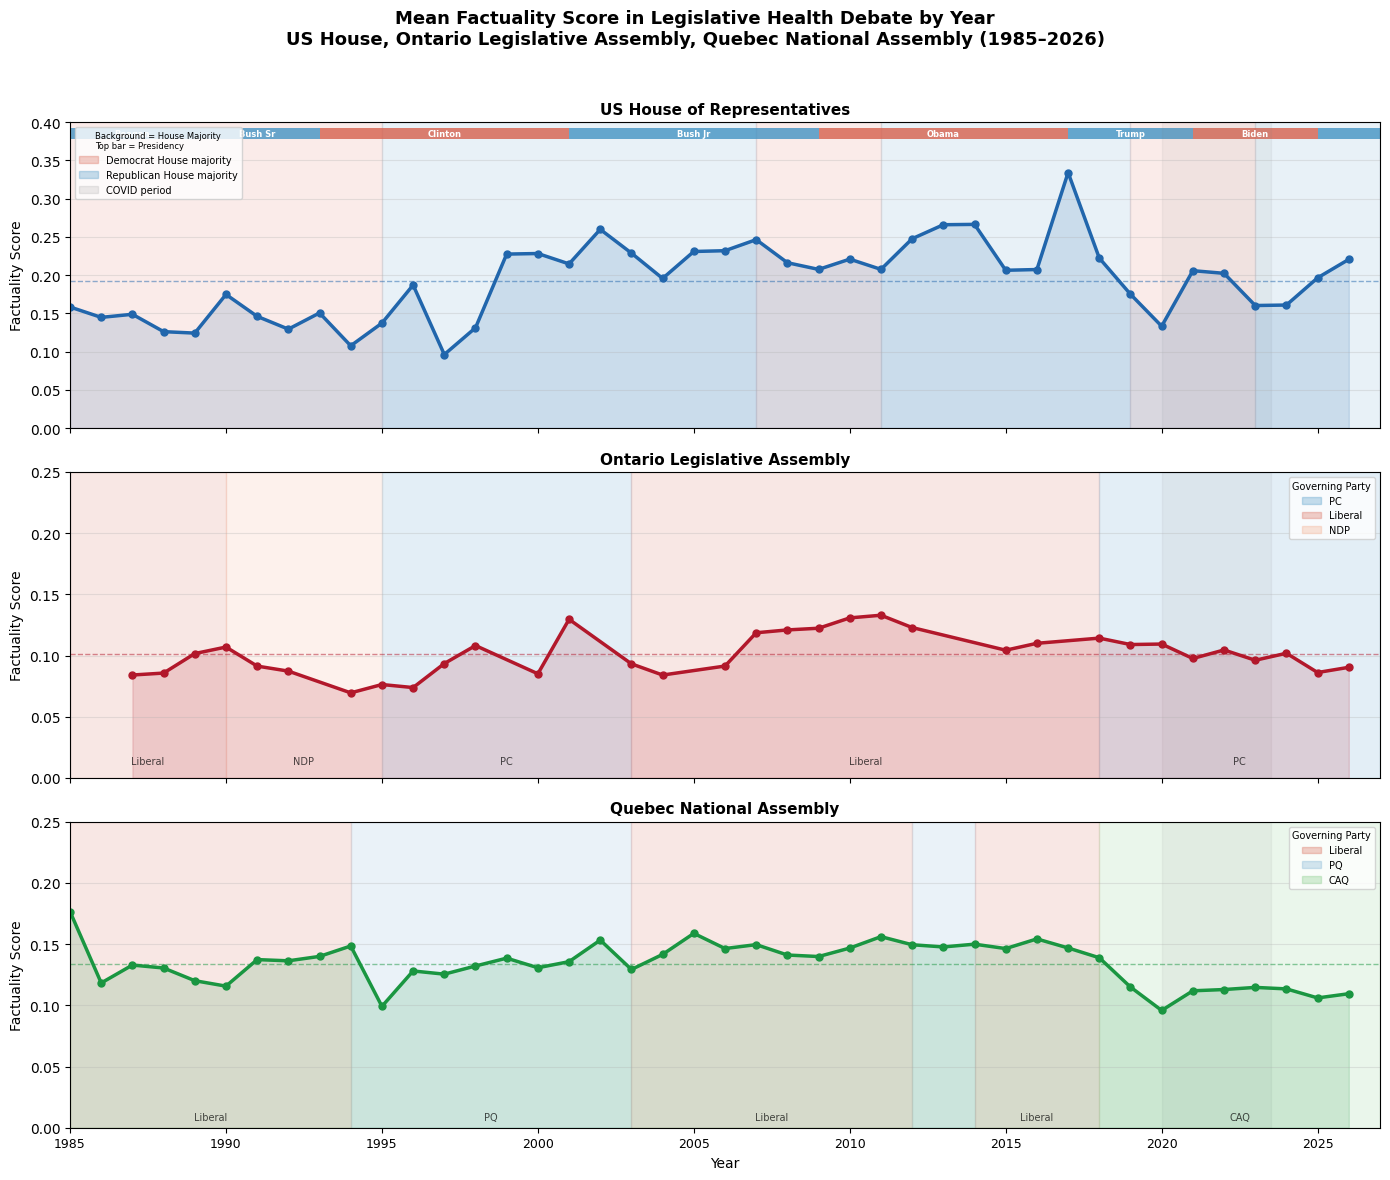

Saved to figures/factuality_over_time.png


In [12]:
# ── FIGURE 1: Three-panel factuality over time ────────────────────────────────

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
fig.suptitle(
    'Mean Factuality Score in Legislative Health Debate by Year\n'
    'US House, Ontario Legislative Assembly, Quebec National Assembly (1985–2026)',
    fontsize=13, fontweight='bold', y=0.98
)

# ── US panel ──────────────────────────────────────────────────────────────────
ax = axes[0]
# Background: House majority
for start, end, party, color in us_house:
    ax.axvspan(start, end, alpha=0.12, color=color)

# Top bar: Presidency (drawn as thin rectangles at top of panel)
bar_height = 0.015  # height in data coordinates
bar_y = 0.385       # just below top of y-axis (ylim=0.4)
for start, end, name, color in us_presidents:
    ax.barh(y=bar_y, width=end-start, left=start, height=bar_height,
            color=color, alpha=0.8, align='center')
    if end - start > 3:
        ax.text((start+end)/2, bar_y, name, ha='center', va='center',
                fontsize=6, color='white', fontweight='bold')

# COVID overlay
ax.axvspan(2020, 2023.5, alpha=0.08, color='gray')
ax.plot(us_yearly['year'], us_yearly['mean'], color='#2166AC', linewidth=2.5,
        marker='o', markersize=5, label='US mean factuality')
ax.fill_between(us_yearly['year'], us_yearly['mean'], alpha=0.15, color='#2166AC')
ax.axhline(us_yearly['mean'].mean(), color='#2166AC', linewidth=1, linestyle='--', alpha=0.5)
ax.set_ylabel('Factuality Score', fontsize=10)
ax.set_title('US House of Representatives', fontsize=11, fontweight='bold')
ax.set_ylim(0, 0.4)
ax.grid(axis='y', alpha=0.3)

# Legend
dem_patch = mpatches.Patch(color='#D6604D', alpha=0.3, label='Democrat House majority')
rep_patch = mpatches.Patch(color='#4393C3', alpha=0.3, label='Republican House majority')
covid_patch = mpatches.Patch(color='gray', alpha=0.15, label='COVID period')
ax.legend(handles=[dem_patch, rep_patch, covid_patch], loc='upper left',
          fontsize=7, title='Background = House Majority\nTop bar = Presidency',
          title_fontsize=6)
# ── Ontario panel ─────────────────────────────────────────────────────────────
ax = axes[1]
# Governing party shading
for start, end, party, color in ont_govs:
    ax.axvspan(start, end, alpha=0.15, color=color)
    mid = (start + end) / 2
    if end - start > 2:
        ax.text(mid, 0.01, party, ha='center', va='bottom', fontsize=7,
                color='black', alpha=0.7)
ax.axvspan(2020, 2023.5, alpha=0.08, color='gray')
ax.plot(ont_yearly['year'], ont_yearly['mean'], color='#B2182B', linewidth=2.5,
        marker='o', markersize=5, label='Ontario mean factuality')
ax.fill_between(ont_yearly['year'], ont_yearly['mean'], alpha=0.15, color='#B2182B')
ax.axhline(ont_yearly['mean'].mean(), color='#B2182B', linewidth=1, linestyle='--', alpha=0.5)
ax.set_ylabel('Factuality Score', fontsize=10)
ax.set_title('Ontario Legislative Assembly', fontsize=11, fontweight='bold')
ax.set_ylim(0, 0.25)
ax.legend(loc='upper left', fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Legend for party shading
pc_patch = mpatches.Patch(color='#4393C3', alpha=0.3, label='PC')
lib_patch = mpatches.Patch(color='#D6604D', alpha=0.3, label='Liberal')
ndp_patch = mpatches.Patch(color='#F4A582', alpha=0.3, label='NDP')
ax.legend(handles=[pc_patch, lib_patch, ndp_patch], loc='upper right', fontsize=7,
          title='Governing Party', title_fontsize=7)

# ── Quebec panel ──────────────────────────────────────────────────────────────
ax = axes[2]
for start, end, party, color in qc_govs:
    ax.axvspan(start, end, alpha=0.15, color=color)
    mid = (start + end) / 2
    if end - start > 2:
        ax.text(mid, 0.005, party, ha='center', va='bottom', fontsize=7,
                color='black', alpha=0.7)
ax.axvspan(2020, 2023.5, alpha=0.08, color='gray')
ax.plot(qc_yearly['year'], qc_yearly['mean'], color='#1A9641', linewidth=2.5,
        marker='o', markersize=5, label='Quebec mean factuality')
ax.fill_between(qc_yearly['year'], qc_yearly['mean'], alpha=0.15, color='#1A9641')
ax.axhline(qc_yearly['mean'].mean(), color='#1A9641', linewidth=1, linestyle='--', alpha=0.5)
ax.set_ylabel('Factuality Score', fontsize=10)
ax.set_xlabel('Year', fontsize=10)
ax.set_title('Quebec National Assembly', fontsize=11, fontweight='bold')
ax.set_ylim(0, 0.25)
ax.legend(loc='upper left', fontsize=8)
ax.grid(axis='y', alpha=0.3)

lib_patch = mpatches.Patch(color='#D6604D', alpha=0.3, label='Liberal')
pq_patch = mpatches.Patch(color='#74ADD1', alpha=0.3, label='PQ')
caq_patch = mpatches.Patch(color='#78C679', alpha=0.3, label='CAQ')
ax.legend(handles=[lib_patch, pq_patch, caq_patch], loc='upper right', fontsize=7,
          title='Governing Party', title_fontsize=7)

# ── Shared x-axis formatting ──────────────────────────────────────────────────
for ax in axes:
    ax.set_xlim(1985, 2027)
    ax.set_xticks(range(1985, 2027, 5))
    ax.tick_params(axis='x', labelsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.96])
import os
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/factuality_over_time.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to figures/factuality_over_time.png')

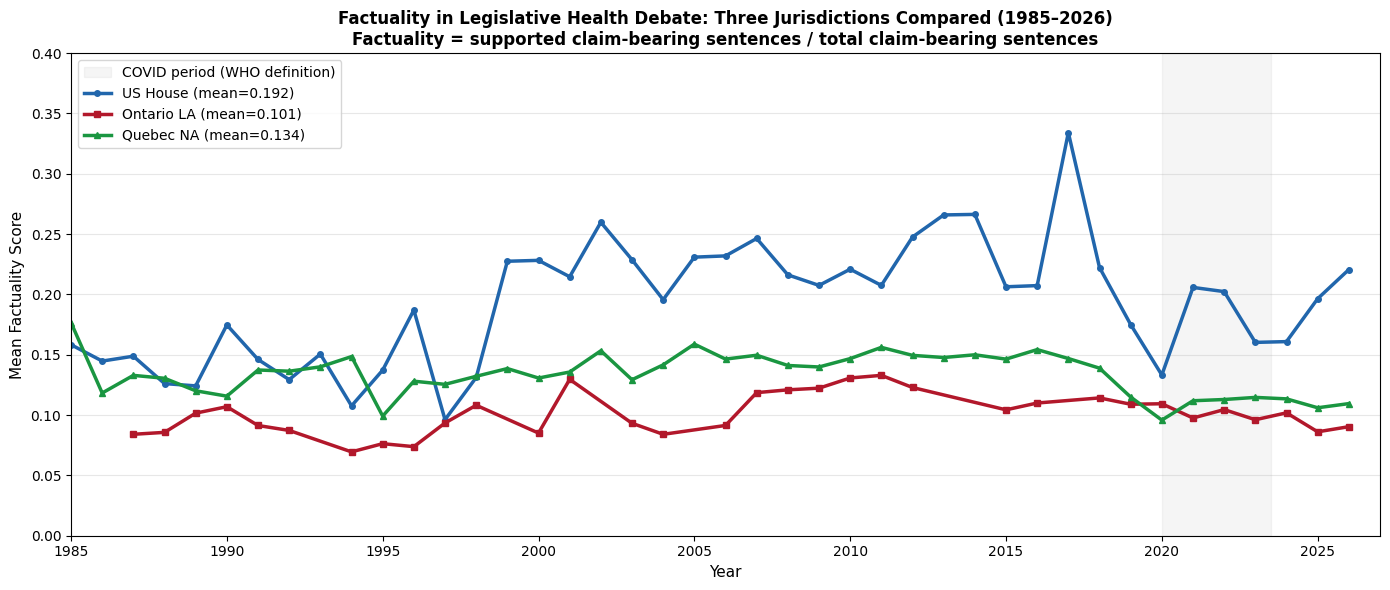

Saved to figures/factuality_comparison.png


In [13]:
# ── FIGURE 2: Combined overlay ────────────────────────────────────────────────
# All three jurisdictions on one axis for direct comparison

fig, ax = plt.subplots(figsize=(14, 6))

ax.axvspan(2020, 2023.5, alpha=0.08, color='gray', label='COVID period (WHO definition)')

ax.plot(us_yearly['year'], us_yearly['mean'], color='#2166AC', linewidth=2.5,
        marker='o', markersize=4, label=f'US House (mean={us_yearly["mean"].mean():.3f})')
ax.plot(ont_yearly['year'], ont_yearly['mean'], color='#B2182B', linewidth=2.5,
        marker='s', markersize=4, label=f'Ontario LA (mean={ont_yearly["mean"].mean():.3f})')
ax.plot(qc_yearly['year'], qc_yearly['mean'], color='#1A9641', linewidth=2.5,
        marker='^', markersize=4, label=f'Quebec NA (mean={qc_yearly["mean"].mean():.3f})')

ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Mean Factuality Score', fontsize=11)
ax.set_title(
    'Factuality in Legislative Health Debate: Three Jurisdictions Compared (1985–2026)\n'
    'Factuality = supported claim-bearing sentences / total claim-bearing sentences',
    fontsize=12, fontweight='bold'
)
ax.set_xlim(1985, 2027)
ax.set_ylim(0, 0.4)
ax.set_xticks(range(1985, 2027, 5))
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/factuality_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to figures/factuality_comparison.png')

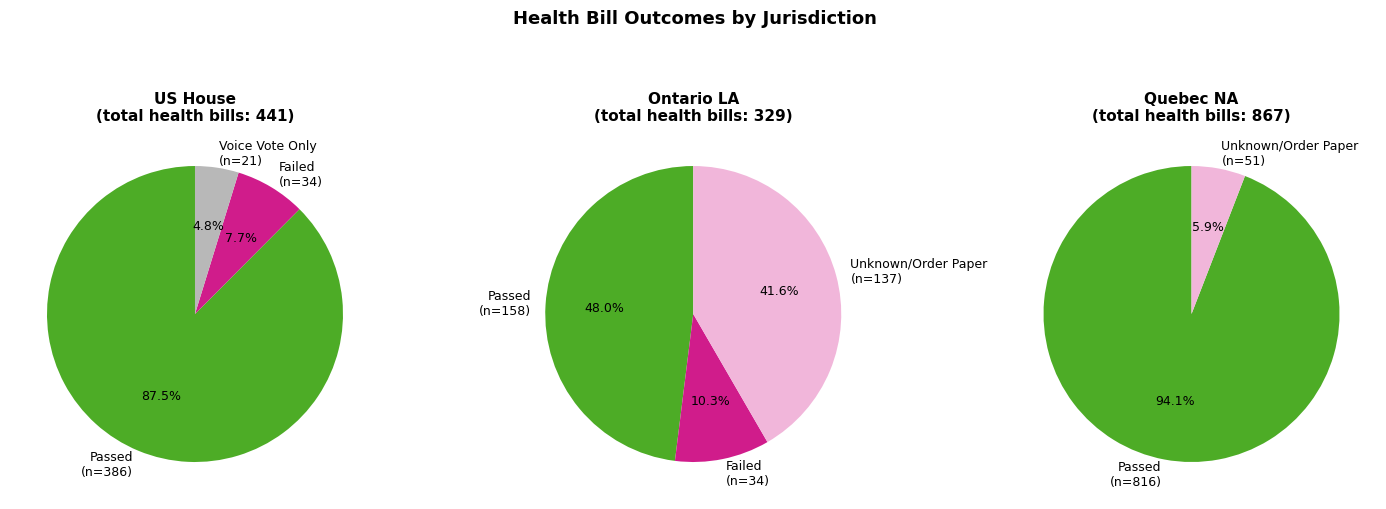

Saved to figures/bill_outcomes_proportions.png


In [14]:
# ── FIGURE 3: Pass rate proportions (comment [30]) ───────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(14, 6))
fig.suptitle('Health Bill Outcomes by Jurisdiction', fontsize=13, fontweight='bold')

data = {
    'US House': {
        'total_bills': 441,
        'scored': 420,
        'passed': 386,
        'failed': 34,
        'unknown': 0,
        'voice_vote': 21,
    },
    'Ontario LA': {
        'total_bills': 329,
        'scored': 329,
        'passed': 158,
        'failed': 34,
        'unknown': 137,
        'voice_vote': 0,
    },
    'Quebec NA': {
        'total_bills': 867,
        'scored': 816,
        'passed': 816,
        'failed': 0,
        'unknown': 51,
        'voice_vote': 0,
    },
}

colors = ['#4DAC26', '#D01C8B', '#F1B6DA', '#B8B8B8']
labels = ['Passed', 'Failed', 'Unknown/Order Paper', 'Voice Vote Only']

for ax, (juris, d) in zip(axes, data.items()):
    sizes = [d['passed'], d['failed'], d['unknown'], d['voice_vote']]
    sizes = [s for s in sizes if s > 0]
    lbls = [f'{l}\n(n={s})' for l, s in zip(labels, 
             [d['passed'], d['failed'], d['unknown'], d['voice_vote']]) if s > 0]
    clrs = [c for c, s in zip(colors, 
             [d['passed'], d['failed'], d['unknown'], d['voice_vote']]) if s > 0]
    
    wedges, texts, autotexts = ax.pie(
        sizes, labels=lbls, colors=clrs,
        autopct='%1.1f%%', startangle=90,
        textprops={'fontsize': 9}
    )
    ax.set_title(f'{juris}\n(total health bills: {d["total_bills"]:,})',
                 fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/bill_outcomes_proportions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to figures/bill_outcomes_proportions.png')